In [ ]:
!pip install cohere pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.4/295.4 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 20.3 MB/s eta 0:00:00
  Attempting uninstall: httpx-sse
    Found existing installation: httpx-sse 0.4.1
    Uninstalling httpx-sse-0.4.1:
      Successfully uninstalled httpx-sse-0.4.1


In [ ]:
import os
import cohere
import pandas as pd
import re
from google.colab import userdata
from helpers.utils import processar_lotes, plot_confusion

os.environ['COHERE_API_KEY'] = userdata.get('COHERE_API_KEY')
co = cohere.ClientV2(api_key=os.environ['COHERE_API_KEY'])

In [ ]:
#carregar base de dados
df = pd.read_csv("/content/hate_speech_classification_tcc/dados/Portuguese_Hate_Speech_Dataset/test.csv")
df['label'].value_counts(normalize=True)

,proportion
label,
0,0.7
1,0.3


## Carregar prompts

In [ ]:
zero_shot_prompt = open("/content/hate_speech_classification_tcc/codigo/prompts/zero_shot/zero_shot.txt", "r").read()
one_shot_prompt = open("/content/hate_speech_classification_tcc/codigo/prompts/one_shot/one_shot.txt", "r").read()
few_shot_prompt = open("/content/hate_speech_classification_tcc/codigo/prompts/few_shot/few_shot.txt", "r").read()

In [ ]:
# Processar lotes
df_final = processar_lotes(df, co, zero_shot_prompt, 'pred_zero_shot', batch_size=20)

classificação com: pred_zero_shot
⏸️ Aguardando para respeitar limite de 10 chamadas/min...


In [ ]:
# Processar lotes
df_final = processar_lotes(df, co, one_shot_prompt, 'pred_one_shot', batch_size=20)

classificação com: pred_one_shot
⏸️ Aguardando para respeitar limite de 10 chamadas/min...


In [ ]:
# Processar lotes
df_final = processar_lotes(df, co, few_shot_prompt, 'pred_few_shot', batch_size=20)

classificação com: pred_few_shot
⏸️ Aguardando para respeitar limite de 10 chamadas/min...


### Avaliação das técnicas de prompt

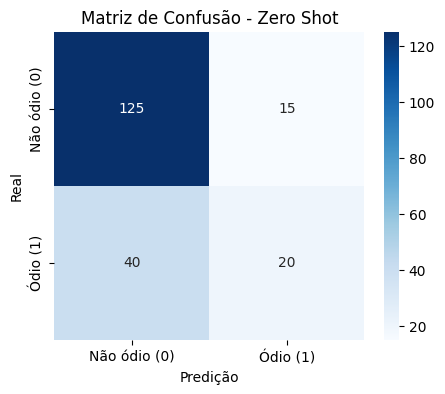


Relatório de Classificação:
              precision    recall  f1-score   support

Não ódio (0)       0.76      0.89      0.82       140
    Ódio (1)       0.57      0.33      0.42        60

    accuracy                           0.72       200
   macro avg       0.66      0.61      0.62       200
weighted avg       0.70      0.72      0.70       200



In [ ]:
# Plotar matriz de confusão
path = '/content/hate_speech_classification_tcc/dados/resultados/generativos/cohere/report_zero_shot.txt'
plot_confusion(df_final["label"], df_final["pred_zero_shot"].astype(int), "Matriz de Confusão - Zero Shot", path)

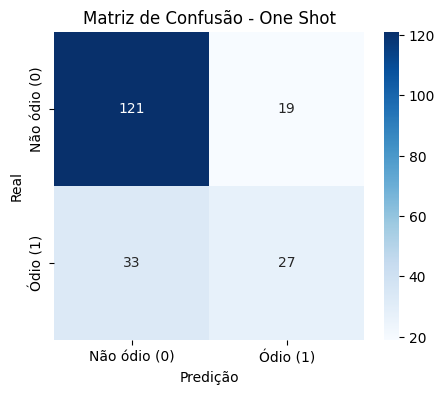


Relatório de Classificação:
              precision    recall  f1-score   support

Não ódio (0)       0.79      0.86      0.82       140
    Ódio (1)       0.59      0.45      0.51        60

    accuracy                           0.74       200
   macro avg       0.69      0.66      0.67       200
weighted avg       0.73      0.74      0.73       200



In [ ]:
# Plotar matriz de confusão
path = '/content/hate_speech_classification_tcc/dados/resultados/generativos/cohere/report_one_shot.txt'
plot_confusion(df_final["label"], df_final["pred_one_shot"].astype(int), "Matriz de Confusão - One Shot", path)

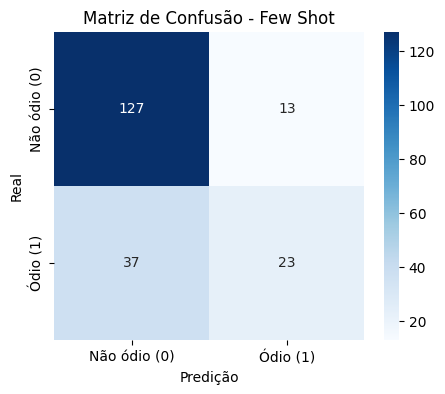


Relatório de Classificação:
              precision    recall  f1-score   support

Não ódio (0)       0.77      0.91      0.84       140
    Ódio (1)       0.64      0.38      0.48        60

    accuracy                           0.75       200
   macro avg       0.71      0.65      0.66       200
weighted avg       0.73      0.75      0.73       200



In [ ]:
# Plotar matriz de confusão
path = '/content/hate_speech_classification_tcc/dados/resultados/generativos/cohere/report_few_shot.txt'
plot_confusion(df_final["label"], df_final["pred_few_shot"].astype(int), "Matriz de Confusão - Few Shot", path)